# Validation des scores de sentiment

Ce notebook valide que notre implémentation du bag-of-words reproduit
les résultats du papier (Czudaj & Nguyen, 2025).

**Checks à effectuer :**
1. Validation manuelle sur la phrase d'exemple du papier (section 3.2)
2. Statistiques descriptives vs Table A3 du papier
3. Comparaison visuelle avec la Figure 2 du papier


In [5]:
from pathlib import Path
import sys
import importlib

project_root = Path('.').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import cleaner as cleaner_module
importlib.reload(cleaner_module)

import dictionary as dictionary_module
importlib.reload(dictionary_module)

import scorer as scorer_module
importlib.reload(scorer_module)
score_document = scorer_module.score_document

from config import PATHS

## 1. Validation manuelle — phrase d'exemple du papier

Le papier (section 3.2) donne l'exemple suivant :

> *"Inflation remains very low in the context of weak demand and significant slack in labour and product markets."*

Score attendu : `t_dovish = 0.33`, `t_hawkish = 0.0`, `t_sentiment = -0.33`

In [6]:
test_sentence = (
    "Inflation remains very low in the context of weak demand "
    "and significant slack in labour and product markets."
)

debug = score_document(test_sentence, return_details=True)
scores = debug["scores"]

print("Scores obtenus :")
for k, v in scores.items():
    print(f"  {k:20s} : {v:.4f}")

# Validation
expected_inflation = -0.33
tol = 0.05
obtained = scores.get('inflation', 0)
status = '✓' if abs(obtained - expected_inflation) < tol else '✗'
print(f"\n{status} Inflation sentiment : obtenu={obtained:.4f}, attendu={expected_inflation:.4f}")

print("\nDétail du calcul (par fenêtre):")
trace_df = pd.DataFrame(debug["trace"])
if not trace_df.empty:
    cols = [
        "keyword", "n_tokens", "keyword_count", "W_ij",
        "hawk_matches", "dove_matches",
        "window_hawkish_score", "window_dovish_score", "window_sentiment",
        "raw_tokens"
    ]
    display(trace_df[cols])
else:
    print("Aucune fenêtre détectée.")

Scores obtenus :
  inflation            : -0.3333
  interest_rate        : 0.0000
  unemployment         : 0.0000
  all                  : -0.3333

✓ Inflation sentiment : obtenu=-0.3333, attendu=-0.3300

Détail du calcul (par fenêtre):


,keyword,n_tokens,keyword_count,W_ij,hawk_matches,dove_matches,window_hawkish_score,window_dovish_score,window_sentiment,raw_tokens
0,inflation,6,1,1.0,0,2,0.0,0.333333,-0.333333,"[inflation, remains, low, context, weak, demand]"


## 2. Statistiques descriptives — comparaison Table A3 du papier

Valeurs attendues :
| Variable | Mean | Std | Min | Max |
|---|---|---|---|---|
| Inflation | 0.06 | 0.51 | -2.94 | 1.80 |
| Interest rate | -0.16 | 0.28 | -1.59 | 0.71 |
| Unemployment | -0.08 | 0.13 | -0.69 | 0.40 |
| All | -0.16 | 0.70 | -3.82 | 2.26 |

In [7]:
scores_df = pd.read_csv(f"{PATHS['scores']}", parse_dates=['date'])
print(f"Nombre de conférences : {len(scores_df)} (attendu : ~266)\n")
print(scores_df[['inflation', 'interest_rate', 'unemployment', 'all']].describe().round(4))

Nombre de conférences : 205 (attendu : ~266)

       inflation  interest_rate  unemployment       all
count   205.0000       205.0000      205.0000  205.0000
mean      0.1294        -0.0456       -0.0820    0.0018
std       0.5371         0.3233        0.1356    0.7344
min      -2.1827        -1.3047       -0.6227   -3.3030
25%      -0.1250        -0.2083       -0.1250   -0.4179
50%       0.0805         0.0000        0.0000    0.0429
75%       0.3750         0.0952        0.0000    0.3353
max       2.0333         1.3702        0.2540    2.0898


## 3. Reproduction de la Figure 2 du papier

Le score agrégé doit être :
- **Hawkish** (~positif) : 2008, 2011, 2021-2022
- **Dovish** (~négatif) : 2013-2014 (début de l'ultra-low rate period)

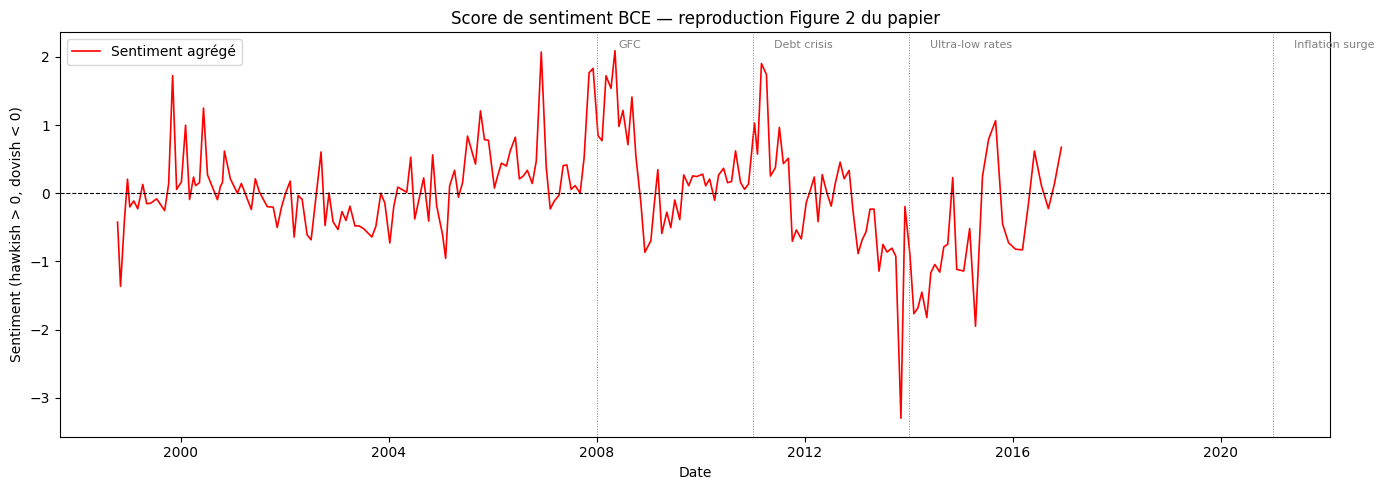

Figure sauvegardée.


In [8]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(scores_df['date'], scores_df['all'], color='red', linewidth=1.2, label='Sentiment agrégé')
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

# Annotations des périodes clés
for year, label in [(2008, 'GFC'), (2011, 'Debt crisis'), (2014, 'Ultra-low rates'), (2021, 'Inflation surge')]:
    ax.axvline(pd.Timestamp(f'{year}-01-01'), color='grey', linewidth=0.7, linestyle=':')
    ax.text(pd.Timestamp(f'{year}-06-01'), ax.get_ylim()[1] * 0.9, label, fontsize=8, color='grey')

ax.set_title('Score de sentiment BCE — reproduction Figure 2 du papier')
ax.set_xlabel('Date')
ax.set_ylabel('Sentiment (hawkish > 0, dovish < 0)')
ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig('data/output/figure2_reproduction.png', dpi=150)
plt.show()
print("Figure sauvegardée.")

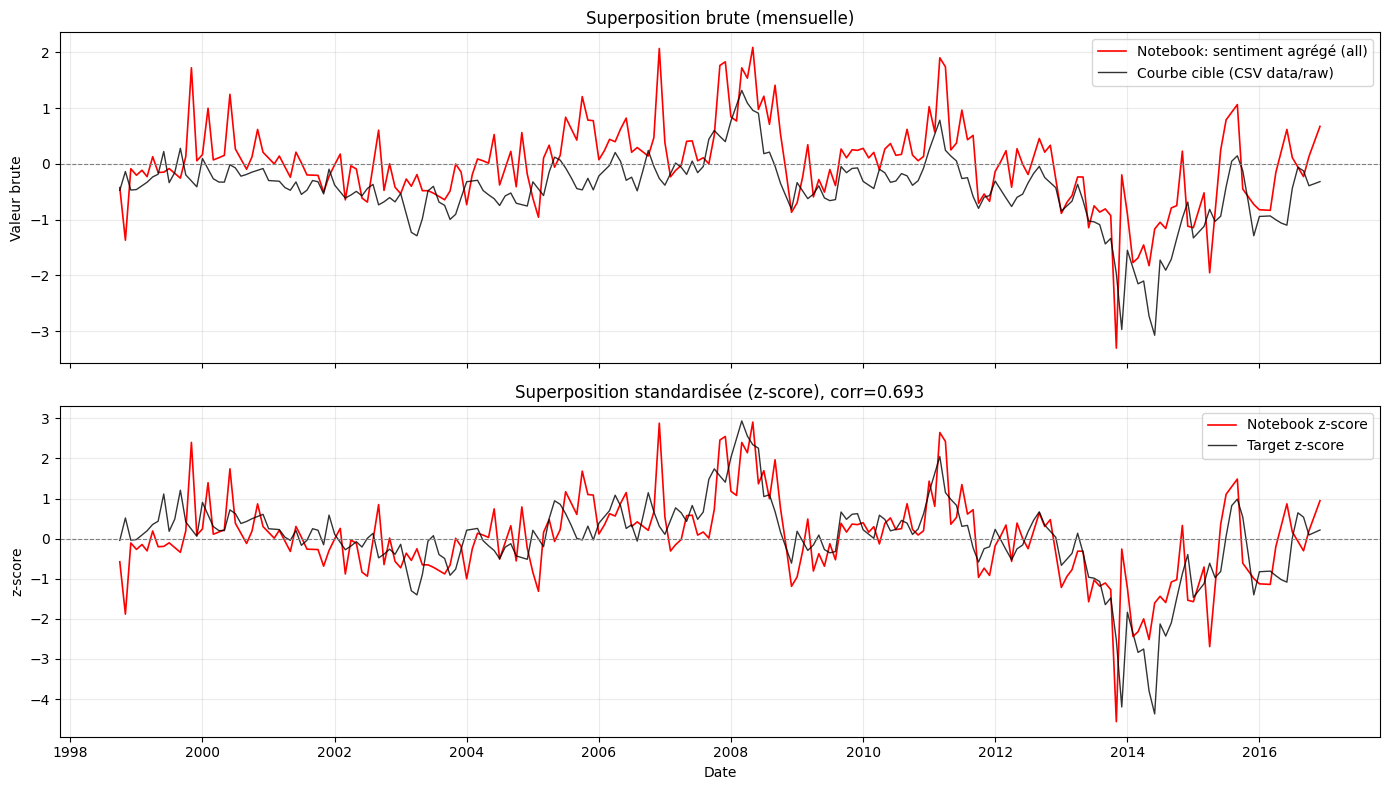

CSV target utilisé: data/raw/sentiment_red_curve.csv
Colonne cible utilisée: sentiment_score
Points alignés: 219
Période: 1998-10-01 -> 2016-12-01
Corrélation z-score: 0.6929


In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

target_path = Path('data/raw/sentiment_red_curve.csv')
model_path = Path(PATHS['scores'])

target = pd.read_csv(target_path, parse_dates=['date'])
model = pd.read_csv(model_path, parse_dates=['date'])

target_col_candidates = ['sentiment_score', 'target_sentiment', 'sentiment', 'score', 'value', 'y']
target_col = next((column for column in target_col_candidates if column in target.columns), None)
if target_col is None:
    raise ValueError(
        f"Aucune colonne cible trouvée dans {target_path}. "
        f"Colonnes attendues: {target_col_candidates}. Colonnes présentes: {list(target.columns)}"
    )

target = target.dropna(subset=['date', target_col]).sort_values('date')
model = model.dropna(subset=['date', 'all']).sort_values('date')

target_monthly = target.set_index('date')[target_col].resample('MS').mean()
model_monthly = model.set_index('date')['all'].resample('MS').mean()

start = max(target_monthly.index.min(), model_monthly.index.min())
end = min(target_monthly.index.max(), model_monthly.index.max())
idx = pd.date_range(start, end, freq='MS')

aligned = pd.DataFrame(index=idx)
aligned['target'] = target_monthly.reindex(idx).interpolate(method='time', limit_area='inside')
aligned['model'] = model_monthly.reindex(idx).interpolate(method='time', limit_area='inside')
aligned = aligned.dropna().copy()

def zscore(s: pd.Series) -> pd.Series:
    std = s.std(ddof=0)
    if std == 0 or np.isnan(std):
        return pd.Series(np.zeros(len(s)), index=s.index)
    return (s - s.mean()) / std

aligned['target_z'] = zscore(aligned['target'])
aligned['model_z'] = zscore(aligned['model'])

corr = aligned[['target_z', 'model_z']].corr().iloc[0, 1]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(aligned.index, aligned['model'], color='red', linewidth=1.2, label='Notebook: sentiment agrégé (all)')
axes[0].plot(aligned.index, aligned['target'], color='black', linewidth=1.0, alpha=0.8, label='Courbe cible (CSV data/raw)')
axes[0].axhline(0, color='grey', linewidth=0.8, linestyle='--')
axes[0].set_title('Superposition brute (mensuelle)')
axes[0].set_ylabel('Valeur brute')
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(aligned.index, aligned['model_z'], color='red', linewidth=1.2, label='Notebook z-score')
axes[1].plot(aligned.index, aligned['target_z'], color='black', linewidth=1.0, alpha=0.8, label='Target z-score')
axes[1].axhline(0, color='grey', linewidth=0.8, linestyle='--')
axes[1].set_title(f'Superposition standardisée (z-score), corr={corr:.3f}')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('z-score')
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print(f'CSV target utilisé: {target_path}')
print(f'Colonne cible utilisée: {target_col}')
print(f'Points alignés: {len(aligned)}')
print(f'Période: {aligned.index.min().date()} -> {aligned.index.max().date()}')
print(f'Corrélation z-score: {corr:.4f}')